# Reading and Merging the Data

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('data/housing_in_london_monthly_variables.csv')
dff = pd.read_csv('data/housing_in_london_yearly_variables.csv')

In [3]:
dff.head()

,code,area,date,median_salary,life_satisfaction,mean_salary,recycling_pct,population_size,number_of_jobs,area_size,no_of_houses,borough_flag
0,E09000001,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
1,E09000002,barking and dagenham,1999-12-01,21480.0,NaN,23620,3,162444.0,NaN,NaN,NaN,1
2,E09000003,barnet,1999-12-01,19568.0,NaN,23128,8,313469.0,NaN,NaN,NaN,1
3,E09000004,bexley,1999-12-01,18621.0,NaN,21386,18,217458.0,NaN,NaN,NaN,1
4,E09000005,brent,1999-12-01,18532.0,NaN,20911,6,260317.0,NaN,NaN,NaN,1


In [4]:
dff['area'].nunique()

51

In [5]:
df.head()

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag
0,1995-01-01,city of london,91449,E09000001,17.0,NaN,1
1,1995-02-01,city of london,82203,E09000001,7.0,NaN,1
2,1995-03-01,city of london,79121,E09000001,14.0,NaN,1
3,1995-04-01,city of london,77101,E09000001,7.0,NaN,1
4,1995-05-01,city of london,84409,E09000001,10.0,NaN,1


In [6]:
df['area'].nunique()

45

In [7]:
df = df[df['date'] >= '1999-01-01']
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
dff['date'] = pd.to_datetime(dff['date'])
dff['year'] = dff['date'].dt.year

In [8]:
merged_df = pd.merge(df, dff, on=['code', 'year'], how='inner')
merged_df.head()

,date_x,area_x,average_price,code,houses_sold,no_of_crimes,borough_flag_x,year,area_y,date_y,median_salary,life_satisfaction,mean_salary,recycling_pct,population_size,number_of_jobs,area_size,no_of_houses,borough_flag_y
0,1999-01-01,city of london,149143,E09000001,41.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
1,1999-02-01,city of london,164545,E09000001,31.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
2,1999-03-01,city of london,174586,E09000001,53.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
3,1999-04-01,city of london,191157,E09000001,28.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
4,1999-05-01,city of london,191081,E09000001,35.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1


In [9]:
area_x_list = merged_df['area_x'].unique().tolist()
print(area_x_list)

['city of london', 'barking and dagenham', 'barnet', 'bexley', 'brent', 'bromley', 'camden', 'croydon', 'ealing', 'enfield', 'greenwich', 'hackney', 'hammersmith and fulham', 'haringey', 'harrow', 'havering', 'hillingdon', 'hounslow', 'islington', 'kensington and chelsea', 'kingston upon thames', 'lambeth', 'lewisham', 'merton', 'newham', 'redbridge', 'richmond upon thames', 'southwark', 'sutton', 'tower hamlets', 'waltham forest', 'wandsworth', 'westminster', 'inner london', 'outer london', 'north east', 'north west', 'yorks and the humber', 'east midlands', 'west midlands', 'east of england', 'london', 'south east', 'south west', 'england']


In [10]:
# Liste der zu entfernenden Areas
areas_to_remove = [
    'inner london', 'outer london', 'north east', 'north west', 
    'yorks and the humber', 'east midlands', 'west midlands', 
    'east of england', 'london', 'south east', 'south west', 'england'
]

# Neues Dataset erstellen, indem die genannten Areas entfernt werden
filtered_df = merged_df[~merged_df['area_x'].isin(areas_to_remove)]
filtered_df

,date_x,area_x,average_price,code,houses_sold,no_of_crimes,borough_flag_x,year,area_y,date_y,median_salary,life_satisfaction,mean_salary,recycling_pct,population_size,number_of_jobs,area_size,no_of_houses,borough_flag_y
0,1999-01-01,city of london,149143,E09000001,41.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
1,1999-02-01,city of london,164545,E09000001,31.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
2,1999-03-01,city of london,174586,E09000001,53.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
3,1999-04-01,city of london,191157,E09000001,28.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
4,1999-05-01,city of london,191081,E09000001,35.0,NaN,1,1999,city of london,1999-12-01,33020.0,NaN,48922,0,6581.0,NaN,NaN,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8311,2019-08-01,westminster,914870,E09000033,156.0,7069.0,1,2019,westminster,2019-12-01,43556.0,NaN,60010,NaN,NaN,NaN,NaN,NaN,1
8312,2019-09-01,westminster,925955,E09000033,169.0,6384.0,1,2019,westminster,2019-12-01,43556.0,NaN,60010,NaN,NaN,NaN,NaN,NaN,1
8313,2019-10-01,westminster,927864,E09000033,168.0,7208.0,1,2019,westminster,2019-12-01,43556.0,NaN,60010,NaN,NaN,NaN,NaN,NaN,1
8314,2019-11-01,westminster,955615,E09000033,150.0,6843.0,1,2019,westminster,2019-12-01,43556.0,NaN,60010,NaN,NaN,NaN,NaN,NaN,1


In [11]:
filtered_df = filtered_df.drop(columns=['area_y', 'date_y', 'borough_flag_y', 'borough_flag_x', 'life_satisfaction'])

In [12]:
filtered_df = filtered_df.rename(columns={
    'area_x': 'area',
    'date_x': 'date'
})

In [13]:
filtered_df.isna().sum()

date                  0
area                  0
average_price         0
code                  0
houses_sold          33
no_of_crimes        909
year                  0
median_salary       120
mean_salary           0
recycling_pct       396
population_size     396
number_of_jobs      792
area_size          1188
no_of_houses       1188
dtype: int64

In [14]:
missing_values_by_area = filtered_df.groupby(['year', 'area']).apply(lambda x: x.isna().sum())
missing_values_by_area

/var/folders/b0/h1xx55fn0m7f9j3k4jxny4nm0000gn/T/ipykernel_10456/1504759689.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  missing_values_by_area = filtered_df.groupby(['year', 'area']).apply(lambda x: x.isna().sum())


date  area  average_price  code  houses_sold  \
year area                                                                 
1999 barking and dagenham     0     0              0     0            0   
     barnet                   0     0              0     0            0   
     bexley                   0     0              0     0            0   
     brent                    0     0              0     0            0   
     bromley                  0     0              0     0            0   
...                         ...   ...            ...   ...          ...   
2019 sutton                   0     0              0     0            1   
     tower hamlets            0     0              0     0            1   
     waltham forest           0     0              0     0            1   
     wandsworth               0     0              0     0            1   
     westminster              0     0              0     0            1   

                           no_of_crimes  year  median_salary  mean_salary  \
year area                                                                   
1999 barking and dagenham            12     0              0            0   
     barnet                          12     0              0            0   
     bexley                          12     0              0            0   
     brent                           12     0              0            0   
     bromley                         12     0              0            0   
...                                 ...   ...            ...          ...   
2019 sutton                           0     0              0            0   
     tower hamlets                    0     0              0            0   
     waltham forest                   0     0              0            0   
     wandsworth                       0     0              0            0   
     westminster                      0     0              0            0   

                           recycling_pct  population_size  number_of_jobs  \
year area                                                                   
1999 barking and dagenham              0                0              12   
     barnet                            0                0              12   
     bexley                            0                0              12   
     brent                             0                0              12   
     bromley                           0                0              12   
...                                  ...              ...             ...   
2019 sutton                           12               12              12   
     tower hamlets                    12               12              12   
     waltham forest                   12               12              12   
     wandsworth                       12               12              12   
     westminster                      12               12              12   

                           area_size  no_of_houses  
year area                                           
1999 barking and dagenham         12            12  
     barnet                       12            12  
     bexley                       12            12  
     brent                        12            12  
     bromley                      12            12  
...                              ...           ...  
2019 sutton                       12            12  
     tower hamlets                12            12  
     waltham forest               12            12  
     wandsworth                   12            12  
     westminster                  12            12  

[693 rows x 14 columns]

In [15]:
missing_values_by_year = filtered_df.groupby('year').apply(lambda x: x.isna().sum())
missing_values_by_year

/var/folders/b0/h1xx55fn0m7f9j3k4jxny4nm0000gn/T/ipykernel_10456/3676254764.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  missing_values_by_year = filtered_df.groupby('year').apply(lambda x: x.isna().sum())


,date,area,average_price,code,houses_sold,no_of_crimes,year,median_salary,mean_salary,recycling_pct,population_size,number_of_jobs,area_size,no_of_houses
year,,,,,,,,,,,,,,
1999,0,0,0,0,0,396,0,0,0,0,0,396,396,396
2000,0,0,0,0,0,396,0,0,0,0,0,0,396,396
2001,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2002,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2003,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2004,0,0,0,0,0,0,0,36,0,0,0,0,0,0
2005,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2006,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2007,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
filtered_df['area'].nunique()

33

In [17]:
filtered_df = filtered_df[filtered_df['year']>= 2001]
filtered_df = filtered_df[filtered_df['year']<= 2018]
filtered_df

,date,area,average_price,code,houses_sold,no_of_crimes,year,median_salary,mean_salary,recycling_pct,population_size,number_of_jobs,area_size,no_of_houses
24,2001-01-01,city of london,284262,E09000001,24.0,0.0,2001,39104.0,62819,0,7359.0,339000.0,315.0,5009.0
25,2001-02-01,city of london,198137,E09000001,37.0,0.0,2001,39104.0,62819,0,7359.0,339000.0,315.0,5009.0
26,2001-03-01,city of london,189033,E09000001,44.0,0.0,2001,39104.0,62819,0,7359.0,339000.0,315.0,5009.0
27,2001-04-01,city of london,205494,E09000001,38.0,0.0,2001,39104.0,62819,0,7359.0,339000.0,315.0,5009.0
28,2001-05-01,city of london,223459,E09000001,30.0,0.0,2001,39104.0,62819,0,7359.0,339000.0,315.0,5009.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8299,2018-08-01,westminster,982356,E09000033,170.0,5466.0,2018,43015.0,63792,22,255324.0,775000.0,2203.0,124509.0
8300,2018-09-01,westminster,1023157,E09000033,156.0,4989.0,2018,43015.0,63792,22,255324.0,775000.0,2203.0,124509.0
8301,2018-10-01,westminster,1025837,E09000033,173.0,5585.0,2018,43015.0,63792,22,255324.0,775000.0,2203.0,124509.0
8302,2018-11-01,westminster,1030332,E09000033,187.0,6082.0,2018,43015.0,63792,22,255324.0,775000.0,2203.0,124509.0


In [18]:
filtered_df = filtered_df.sort_values(by=['area', 'date'])
filtered_df = filtered_df.groupby('area').apply(lambda group: group.fillna(method='ffill')).reset_index(drop=True)
filtered_df

/var/folders/b0/h1xx55fn0m7f9j3k4jxny4nm0000gn/T/ipykernel_10456/1028291541.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  filtered_df = filtered_df.groupby('area').apply(lambda group: group.fillna(method='ffill')).reset_index(drop=True)
/var/folders/b0/h1xx55fn0m7f9j3k4jxny4nm0000gn/T/ipykernel_10456/1028291541.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  filtered_df = filtered_df.groupby('area').apply(lambda group: group.fillna(method='ffill')).reset_index(drop=True)


,date,area,average_price,code,houses_sold,no_of_crimes,year,median_salary,mean_salary,recycling_pct,population_size,number_of_jobs,area_size,no_of_houses
0,2001-01-01,barking and dagenham,82343,E09000002,215.0,1771.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0
1,2001-02-01,barking and dagenham,83266,E09000002,238.0,1600.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0
2,2001-03-01,barking and dagenham,84058,E09000002,274.0,1759.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0
3,2001-04-01,barking and dagenham,83965,E09000002,241.0,1643.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0
4,2001-05-01,barking and dagenham,85124,E09000002,283.0,1809.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7123,2018-08-01,westminster,982356,E09000033,170.0,5466.0,2018,43015.0,63792,22,255324.0,775000.0,2203.0,124509.0
7124,2018-09-01,westminster,1023157,E09000033,156.0,4989.0,2018,43015.0,63792,22,255324.0,775000.0,2203.0,124509.0
7125,2018-10-01,westminster,1025837,E09000033,173.0,5585.0,2018,43015.0,63792,22,255324.0,775000.0,2203.0,124509.0
7126,2018-11-01,westminster,1030332,E09000033,187.0,6082.0,2018,43015.0,63792,22,255324.0,775000.0,2203.0,124509.0


In [20]:
import geopandas as gpd

# Lade die GeoPackage-Datei
gpkg_path = 'data/London_Boroughs.gpkg'  # Passe den Pfad an
boroughs_gdf = gpd.read_file(gpkg_path)

# Zeige die ersten Zeilen an, um die Struktur zu überprüfen
boroughs_gdf.head()

,objectid,name,gss_code,hectares,nonld_area,ons_inner,sub_2011,geometry
0,1,Kingston upon Thames,E09000021,3726.117,0.000,F,South,"POLYGON ((516401.6 160201.8, 516407.3 160210.5..."
1,2,Croydon,E09000008,8649.441,0.000,F,South,"POLYGON ((535009.2 159504.7, 535005.5 159502, ..."
2,3,Bromley,E09000006,15013.487,0.000,F,South,"POLYGON ((540373.6 157530.4, 540361.2 157551.9..."
3,4,Hounslow,E09000018,5658.541,60.755,F,West,"POLYGON ((509703.4 175356.6, 509712.6 175361.8..."
4,5,Ealing,E09000009,5554.428,0.000,F,West,"POLYGON ((515647.2 178787.8, 515608.8 178787.3..."


In [21]:
boroughs_gdf['name'] = boroughs_gdf['name'].str.lower()

In [22]:
filtered_df = filtered_df.merge(boroughs_gdf[['name', 'geometry']], left_on='area', right_on='name', how='left')
filtered_df = filtered_df.drop(columns=['name']) 
filtered_df.head()

,date,area,average_price,code,houses_sold,no_of_crimes,year,median_salary,mean_salary,recycling_pct,population_size,number_of_jobs,area_size,no_of_houses,geometry
0,2001-01-01,barking and dagenham,82343,E09000002,215.0,1771.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."
1,2001-02-01,barking and dagenham,83266,E09000002,238.0,1600.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."
2,2001-03-01,barking and dagenham,84058,E09000002,274.0,1759.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."
3,2001-04-01,barking and dagenham,83965,E09000002,241.0,1643.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."
4,2001-05-01,barking and dagenham,85124,E09000002,283.0,1809.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."


# EDA

In [23]:
filtered_df.head()

,date,area,average_price,code,houses_sold,no_of_crimes,year,median_salary,mean_salary,recycling_pct,population_size,number_of_jobs,area_size,no_of_houses,geometry
0,2001-01-01,barking and dagenham,82343,E09000002,215.0,1771.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."
1,2001-02-01,barking and dagenham,83266,E09000002,238.0,1600.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."
2,2001-03-01,barking and dagenham,84058,E09000002,274.0,1759.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."
3,2001-04-01,barking and dagenham,83965,E09000002,241.0,1643.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."
4,2001-05-01,barking and dagenham,85124,E09000002,283.0,1809.0,2001,22323.0,26050,3,165654.0,54000.0,3780.0,68298.0,"POLYGON ((545802 181308.8, 545798.4 181496.1, ..."


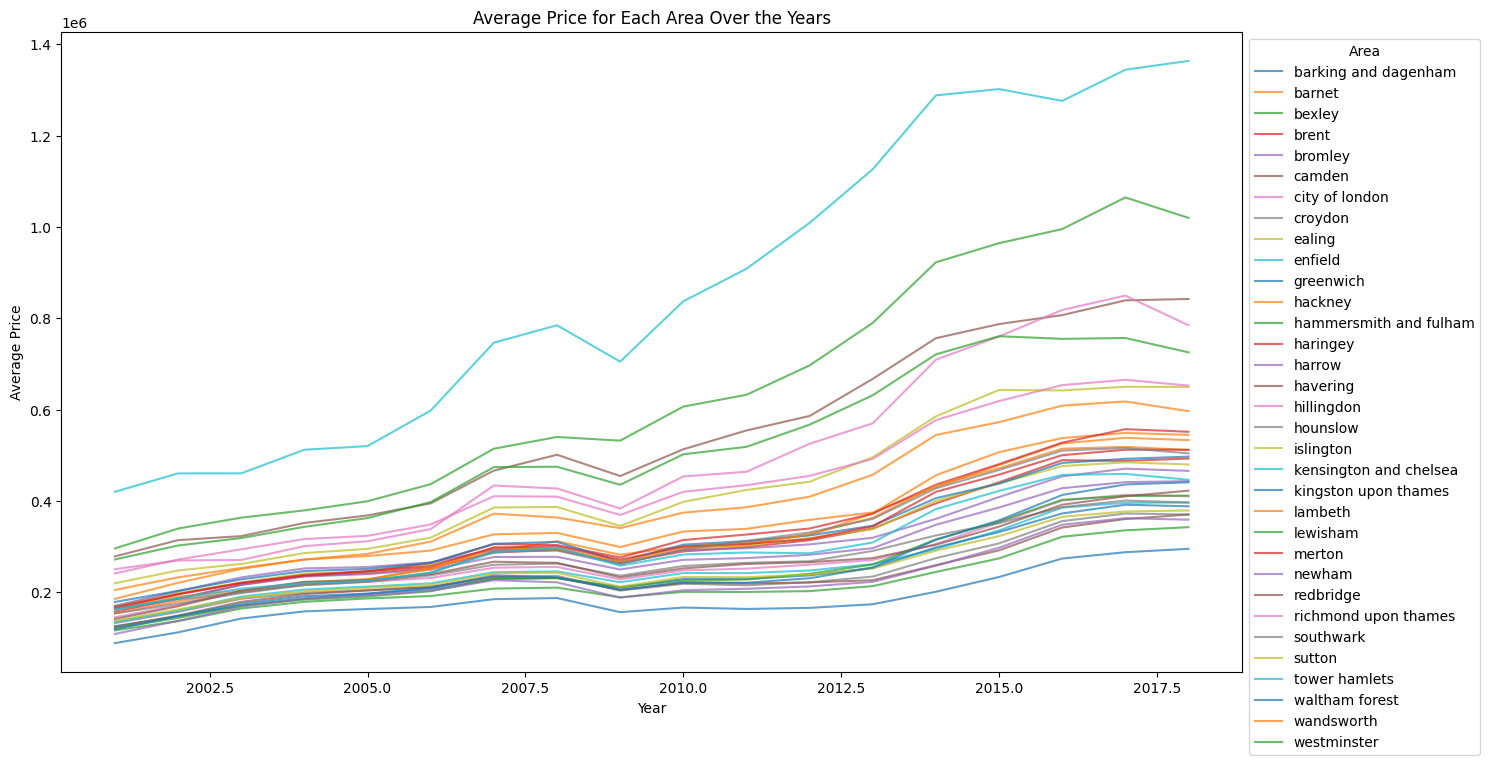

In [24]:
import matplotlib.pyplot as plt

# Group the data by area and year, and calculate the mean average price
grouped_data = filtered_df.groupby(['year', 'area'])['average_price'].mean().unstack()

# Plot the data
plt.figure(figsize=(15, 8))
grouped_data.plot(ax=plt.gca(), legend=False, alpha=0.7)
plt.title('Average Price for Each Area Over the Years')
plt.xlabel('Year')
plt.ylabel('Average Price')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Area')
plt.tight_layout()
plt.show()

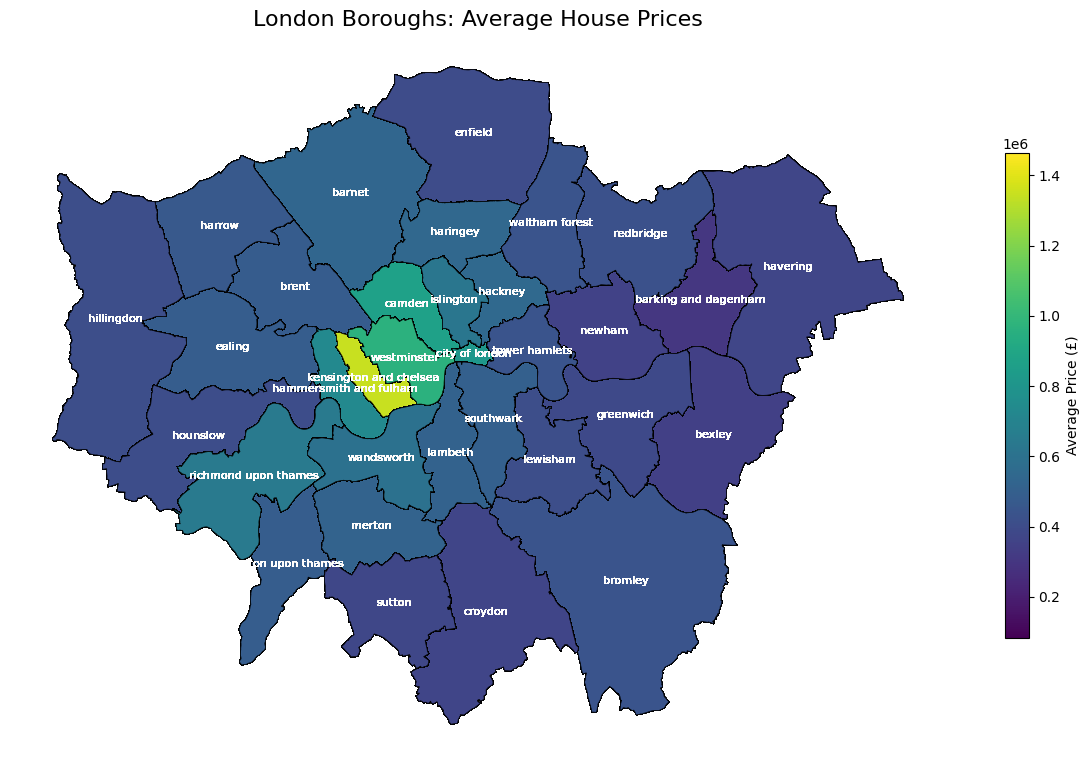

In [25]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Sicherstellen, dass die Daten ein GeoDataFrame sind (falls nicht bereits geschehen)
gdf = gpd.GeoDataFrame(filtered_df, geometry='geometry')

# Karte plotten
fig, ax = plt.subplots(figsize=(12, 10))

# Boroughs mit Farben nach Durchschnittspreis darstellen
gdf.plot(ax=ax, column='average_price', legend=True, 
         legend_kwds={'label': "Average Price (£)", 'shrink': 0.5},
         cmap='viridis', edgecolor='black', linewidth=0.5)

# Titel und Beschriftungen hinzufügen
ax.set_title("London Boroughs: Average House Prices", fontsize=16)
ax.set_axis_off()  # Achsen ausblenden

# Borough-Namen als Annotationen hinzufügen (optional)
for idx, row in gdf.iterrows():
    centroid = row['geometry'].centroid
    ax.text(centroid.x, centroid.y, row['area'], fontsize=8, 
            ha='center', va='center', color='white')

plt.tight_layout()
plt.show()